# Modelo 1: Regresión logística — Telco Customer Churn (P2)

**Propósito:** entrenar, ajustar e interpretar una regresión logística para predecir `Churn`, siguiendo el protocolo definido en `P02_baseline_diseno_experimental.ipynb`.

**Qué se hace en este notebook:**

1. Se arma un `Pipeline` con el preprocesador compartido (`make_preprocessor("logistic")` de `preprocessing.py`) y el clasificador.
2. Se evalúan 36 configuraciones (tipo de regularización, intensidad `C` y `class_weight`); cada una se entrena con **Train** y se mide en **Validation**.
3. Se elige la configuración con mayor **F1-score de `Churn=1` en Validation** y se interpreta el modelo resultante (coeficientes, razones de odds e importancia por permutación).

**Ejecución:** seguir las celdas en orden. Funciona desde la raíz del repositorio, desde `notebooks/` o en Google Colab (el repositorio se clona solo si hace falta). El código reutilizable está en la carpeta `src/`.

> **Importante:** este notebook **no usa Test**. Los tres modelos se evalúan una sola vez sobre Test en `P05_evaluacion_comparativa.ipynb`, cuando las configuraciones ya están cerradas.

## 1. Importación de librerías y localización del proyecto

In [1]:
import sys
import subprocess
import time
from pathlib import Path

# Se busca la raíz del repositorio en el directorio actual, en el directorio padre
# y en las ubicaciones habituales (misma lógica que en P02).
PROJECT_NAME = "Machine-Learning-Project"
REPO_URL = "https://github.com/sofkp/Machine-Learning-Project.git"

candidatos = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd() / PROJECT_NAME,
    Path.cwd().parent / PROJECT_NAME,
    Path("/content") / PROJECT_NAME,
]


def es_raiz(ruta):
    return (ruta / "preprocessing.py").is_file() and (ruta / "src" / "protocolo.py").is_file()


ROOT = next((ruta.resolve() for ruta in candidatos if es_raiz(ruta)), None)

# En Colab, si el repositorio todavía no está en el entorno, se clona.
if ROOT is None and "google.colab" in sys.modules:
    destino = Path("/content") / PROJECT_NAME
    if not destino.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(destino)], check=True)
    if es_raiz(destino):
        ROOT = destino.resolve()

if ROOT is None:
    raise FileNotFoundError(
        "No se encontró el repositorio (preprocessing.py y la carpeta src/). "
        "Clónalo y ejecuta este notebook desde su raíz o desde notebooks/."
    )

sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import analisis, graficos
from src.modelos import (
    GRILLA_LOGISTICA,
    PASO_MODELO,
    crear_regresion_logistica,
    describir_logistica,
    desempate_logistica,
)
from src.protocolo import (
    METRICAS,
    NOMBRE_DUMMY,
    NOMBRE_LOGISTICA,
    RESULTS_DIR,
    buscar_en_validacion,
    cargar_train_validation,
    evaluar_modelo,
    guardar_json,
    guardar_tabla,
    matriz_confusion,
    predecir,
    seleccionar_configuracion,
    tabla_metricas,
    versiones,
)

graficos.aplicar_estilo()
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

print("Carpeta del proyecto:", ROOT.name)
print("Versiones:", versiones())

Carpeta del proyecto: Machine-Learning-Project
Versiones: {'python': '3.12.13', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1'}


## 2. Datos y particiones

Se usan las mismas particiones estratificadas 60/20/20 de `split_data()` (semilla 42). La función `cargar_train_validation()` llama a `load_data()` y `split_data()` y **descarta Test dentro de la función**, de modo que en este notebook no existe ninguna variable con esos datos.

In [2]:
X_train, X_val, y_train, y_val = cargar_train_validation()

print("Train:     ", X_train.shape, "| abandono:", round(y_train.mean(), 4))
print("Validation:", X_val.shape, "| abandono:", round(y_val.mean(), 4))

# Pesos que usa class_weight="balanced": n / (2 * n_clase), calculados solo con Train.
conteos = y_train.value_counts().sort_index()
pesos = len(y_train) / (2 * conteos)
print("\nClientes por clase en Train:", conteos.to_dict())
print("Pesos con class_weight='balanced':", pesos.round(3).to_dict())

Train:      (4225, 19) | abandono: 0.2653
Validation: (1409, 19) | abandono: 0.2654

Clientes por clase en Train: {0: 3104, 1: 1121}
Pesos con class_weight='balanced': {0: 0.681, 1: 1.884}


## 3. Modelo y pipeline

La regresión logística estima la probabilidad de abandono como

$$P(\text{Churn}=1 \mid x) = \sigma(\beta_0 + \beta^\top x), \qquad \sigma(z) = \frac{1}{1 + e^{-z}},$$

es decir, un modelo **lineal en el logaritmo de los odds**. Los coeficientes se obtienen minimizando la pérdida logística más un término de regularización cuya fuerza es $1/C$.

**Preprocesamiento (dentro del `Pipeline`, ajustado solo con Train):**

- `tenure`, `MonthlyCharges` y `TotalCharges` se estandarizan. Es necesario porque la regularización penaliza el tamaño de los coeficientes: si las variables estuvieran en escalas distintas, la penalización las trataría de forma desigual.
- Los 11 faltantes de `TotalCharges` (clientes con `tenure = 0`) se reemplazan por 0 antes de estandarizar.
- Las 16 variables categóricas se codifican con One-Hot Encoding (46 columnas en total).

**Hiperparámetros que se exploran:**

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| Penalización | L2, L1 | L2 encoge todos los coeficientes; L1 puede llevar algunos exactamente a cero (selección de variables). |
| `C` | 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10 | Inverso de la fuerza de regularización, en escala logarítmica. `C` pequeño = modelo más simple. |
| `class_weight` | `None`, `"balanced"` | Tratamiento del desbalance: `"balanced"` da más peso a los errores sobre `Churn=1` (la clase minoritaria). |

Son 2 × 9 × 2 = **36 configuraciones**. No se usan SMOTE ni otros remuestreos, y el umbral queda fijo en 0,5 (acuerdos de P02).

**Detalles de implementación:** L2 se ajusta con `lbfgs` y L1 con `saga`, porque ambos optimizan la misma función sin penalizar el intercepto (`liblinear` sí lo penaliza, lo que distorsiona los resultados cuando `C` es pequeño). Se usa `max_iter=20000` y `tol=1e-7` para que ningún resultado dependa de una convergencia incompleta, y `random_state=42`.

In [3]:
ejemplo = crear_regresion_logistica(penalizacion="l2", class_weight=None, C=1.0)
print("Pasos del Pipeline:")
for nombre, paso in ejemplo.steps:
    print(f" - {nombre}: {type(paso).__name__}")
print("\nClasificador:", ejemplo.named_steps[PASO_MODELO])

Pasos del Pipeline:
 - preprocesamiento: ColumnTransformer
 - modelo: LogisticRegression

Clasificador: LogisticRegression(max_iter=20000, random_state=42, tol=1e-07)


## 4. Grilla de hiperparámetros

La grilla se definió en `src/modelos.py` **antes** de ejecutar los experimentos. Su orden (penalización → `class_weight` → `C` ascendente) es el último criterio de desempate, tal como pide P02.

In [4]:
# None se muestra como texto para que la tabla sea legible.
grilla = pd.DataFrame([{k: ("None" if v is None else v) for k, v in cfg.items()} for cfg in GRILLA_LOGISTICA])
grilla.index = grilla.index + 1
grilla.index.name = "Configuración"
print("Configuraciones:", len(grilla))
for hiperparametro in grilla.columns:
    print(f" - {hiperparametro}: {pd.unique(grilla[hiperparametro]).tolist()}")
print("\nPrimeras y últimas configuraciones, en el orden de la grilla:")
display(pd.concat([grilla.head(3), grilla.tail(3)]))

Configuraciones: 36
 - penalizacion: ['l2', 'l1']
 - class_weight: ['None', 'balanced']
 - C: [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]

Primeras y últimas configuraciones, en el orden de la grilla:


,penalizacion,class_weight,C
Configuración,,,
1,l2,None,0.001
2,l2,None,0.003
3,l2,None,0.010
34,l1,balanced,1.000
35,l1,balanced,3.000
36,l1,balanced,10.000


## 5. Búsqueda con validación fija

`buscar_en_validacion()` recorre la grilla con un bucle explícito: para cada configuración crea un `Pipeline` nuevo, lo ajusta **solo con Train** y calcula las cinco métricas en Train y en Validation. Las métricas de Train se guardan únicamente para medir la brecha Train–Validation; no intervienen en la selección.

In [5]:
inicio = time.time()
tabla = buscar_en_validacion(
    crear_regresion_logistica, GRILLA_LOGISTICA, X_train, y_train, X_val, y_val, describir=describir_logistica
)
print(f"Búsqueda completada en {time.time() - inicio:.1f} s")
print("Configuraciones evaluadas:", len(tabla))
print("Todas convergieron:", bool(tabla["Convergió"].all()))

Búsqueda completada en 14.2 s
Configuraciones evaluadas: 36
Todas convergieron: True


In [6]:
columnas = [
    "Configuración", "penalizacion", "class_weight", "C",
    "F1-score (Train)", "F1-score (Validation)", "Precision (Validation)", "Recall (Validation)",
    "Accuracy (Validation)", "ROC-AUC (Validation)", "Coeficientes no nulos",
]
print("Resultados de las 36 configuraciones (la tabla completa, con todas las métricas, se exporta a CSV):")
display(tabla[columnas].round(4).set_index("Configuración"))

Resultados de las 36 configuraciones (la tabla completa, con todas las métricas, se exporta a CSV):


,penalizacion,class_weight,C,F1-score (Train),F1-score (Validation),Precision (Validation),Recall (Validation),Accuracy (Validation),ROC-AUC (Validation),Coeficientes no nulos
Configuración,,,,,,,,,,
1,l2,None,0.001,0.3390,0.2876,0.7765,0.1765,0.7679,0.8309,46
2,l2,None,0.003,0.5339,0.5185,0.7000,0.4118,0.7970,0.8336,46
3,l2,None,0.010,0.5873,0.5754,0.6775,0.5000,0.8041,0.8349,46
4,l2,None,0.030,0.5915,0.5823,0.6773,0.5107,0.8055,0.8351,46
5,l2,None,0.100,0.5958,0.5838,0.6633,0.5214,0.8027,0.8357,46
6,l2,None,0.300,0.6001,0.5896,0.6611,0.5321,0.8034,0.8358,46
7,l2,None,1.000,0.6010,0.5900,0.6579,0.5348,0.8027,0.8360,46
8,l2,None,3.000,0.6051,0.5900,0.6579,0.5348,0.8027,0.8363,46
9,l2,None,10.000,0.6054,0.5920,0.6590,0.5374,0.8034,0.8366,46


## 6. Selección de la configuración

In [7]:
numero, parametros, empatadas = seleccionar_configuracion(tabla, GRILLA_LOGISTICA, desempate_logistica)

print("Configuración seleccionada:", numero)
print("Hiperparámetros:", parametros)
print("Configuraciones con el mismo F1 máximo:", empatadas)

print("\nLas cinco mejores configuraciones según F1-score en Validation:")
display(
    tabla.sort_values("F1-score (Validation)", ascending=False, kind="mergesort")
    .head(5)[columnas].round(4).set_index("Configuración")
)

Configuración seleccionada: 14
Hiperparámetros: {'penalizacion': 'l2', 'class_weight': 'balanced', 'C': 0.1}
Configuraciones con el mismo F1 máximo: 1

Las cinco mejores configuraciones según F1-score en Validation:


,penalizacion,class_weight,C,F1-score (Train),F1-score (Validation),Precision (Validation),Recall (Validation),Accuracy (Validation),ROC-AUC (Validation),Coeficientes no nulos
Configuración,,,,,,,,,,
14,l2,balanced,0.10,0.6375,0.6251,0.5166,0.7914,0.7480,0.8360,46
15,l2,balanced,0.30,0.6391,0.6245,0.5157,0.7914,0.7473,0.8360,46
30,l1,balanced,0.01,0.6186,0.6245,0.5157,0.7914,0.7473,0.8270,7
16,l2,balanced,1.00,0.6389,0.6237,0.5157,0.7888,0.7473,0.8363,46
12,l2,balanced,0.01,0.6332,0.6233,0.5187,0.7807,0.7495,0.8352,46


**Lectura.** La configuración elegida es la **14: regularización L2, `class_weight="balanced"` y `C = 0.1`**, con F1 = 0.625 en Validation. No hubo empate, así que no fue necesario aplicar la regla de desempate.

Dos detalles que conviene tener presentes:

- `C = 0.1` está en el interior del rango explorado (no en un borde), por lo que no hay señales de que el óptimo quede fuera de la grilla.
- Las cinco mejores configuraciones difieren en menos de 0.003 de F1. La elección exacta entre ellas no es crítica: el desempeño forma una meseta.

## 7. Efecto de la regularización y del tratamiento del desbalance

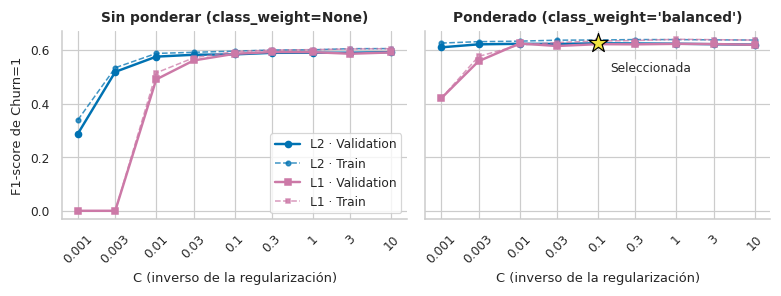

In [8]:
figura = graficos.figura_busqueda_logistica(tabla, numero)
graficos.guardar_figura(figura, "p03_busqueda_regresion_logistica.png")
plt.show()

In [9]:
# Mejor configuración de cada combinación (penalización, class_weight)
mejores = (
    tabla.sort_values("F1-score (Validation)", ascending=False, kind="mergesort")
    .groupby(["penalizacion", "class_weight"], sort=False)
    .head(1)
)
display(mejores[columnas].round(4).set_index("Configuración"))

# Con L1, ¿cuántos coeficientes quedan distintos de cero?
print("Regularización L1 con class_weight='balanced': coeficientes distintos de cero (de 46)")
display(
    tabla[(tabla["penalizacion"] == "l1") & (tabla["class_weight"] == "balanced")]
    [["C", "Coeficientes no nulos", "F1-score (Validation)", "ROC-AUC (Validation)"]]
    .round(4).set_index("C").T
)

brecha = tabla["F1-score (Train)"] - tabla["F1-score (Validation)"]
utiles = tabla["F1-score (Validation)"] > 0.55
print(
    "Brecha Train-Validation de F1 en las configuraciones con F1 > 0.55:",
    f"mínima {brecha[utiles].min():.3f}, máxima {brecha[utiles].max():.3f}",
)

,penalizacion,class_weight,C,F1-score (Train),F1-score (Validation),Precision (Validation),Recall (Validation),Accuracy (Validation),ROC-AUC (Validation),Coeficientes no nulos
Configuración,,,,,,,,,,
14,l2,balanced,0.10,0.6375,0.6251,0.5166,0.7914,0.7480,0.8360,46
30,l1,balanced,0.01,0.6186,0.6245,0.5157,0.7914,0.7473,0.8270,7
24,l1,None,0.30,0.5999,0.5926,0.6645,0.5348,0.8048,0.8364,33
9,l2,None,10.00,0.6054,0.5920,0.6590,0.5374,0.8034,0.8366,46


Regularización L1 con class_weight='balanced': coeficientes distintos de cero (de 46)


C,0.001,0.003,0.010,0.030,0.100,0.300,1.000,3.000,10.000
Coeficientes no nulos,0.0000,2.0000,7.0000,16.0000,22.0000,29.0000,30.0000,34.0000,35.0000
F1-score (Validation),0.4195,0.5583,0.6245,0.6151,0.6220,0.6212,0.6230,0.6224,0.6196
ROC-AUC (Validation),0.5000,0.7889,0.8270,0.8351,0.8365,0.8364,0.8363,0.8364,0.8369


Brecha Train-Validation de F1 en las configuraciones con F1 > 0.55: mínima -0.006, máxima 0.018


**Regularización.** Cuando `C` es muy pequeño el modelo queda subajustado: con L2 y `C = 0.001` sin ponderar, el F1 cae a 0.288 (Recall de 0.176), y con L1 y `C ≤ 0.003` casi todos los coeficientes se anulan. El caso extremo es L1 con `C = 0.001`: no queda ningún coeficiente, el modelo se reduce al intercepto y predice lo mismo para todos los clientes (ROC-AUC = 0.5). A partir de `C ≈ 0.01–0.03` el F1 se estabiliza y ya no mejora al regularizar menos. La brecha entre Train y Validation es pequeña en toda la meseta (menos de 0.02 en todas las configuraciones con F1 > 0.55), lo que indica que este modelo tiene poca varianza: con 4225 clientes y 46 columnas, la regresión logística no llega a sobreajustar.

**L1 frente a L2.** En su mejor punto rinden prácticamente igual (0.6245 frente a 0.6251). Lo interesante de L1 es que con `C = 0.01` alcanza ese F1 usando **solo 7 coeficientes distintos de cero**, aunque con un ROC-AUC algo menor (0.827 frente a 0.836): un modelo mucho más corto detecta casi lo mismo con el umbral de 0,5, pero ordena un poco peor a los clientes.

**Desbalance.** Es el hiperparámetro que más cambia el resultado. Sin ponderar, el mejor F1 es 0.593 (Precision ≈ 0.66, Recall ≈ 0.53); con `class_weight="balanced"` sube a 0.625 (Precision ≈ 0.52, Recall ≈ 0.79). El ROC-AUC es casi el mismo en ambos casos (≈ 0.836), así que ponderar **no mejora la capacidad de ordenar clientes**: lo que hace es desplazar el punto de decisión, de forma parecida a bajar el umbral. Se detectan muchos más abandonos a cambio de más falsas alarmas, y el Accuracy baja de 0.80 a 0.75. Por eso el Accuracy no era un buen criterio de selección.

## 8. Modelo seleccionado: resultados en Validation

In [10]:
modelo = crear_regresion_logistica(**parametros)
modelo.fit(X_train, y_train)  # preprocesador y clasificador se ajustan solo con Train

metricas_train = evaluar_modelo(modelo, X_train, y_train)
y_val_pred, y_val_proba = predecir(modelo, X_val)
metricas_val = evaluar_modelo(modelo, X_val, y_val)

# El modelo reajustado debe reproducir la fila correspondiente de la búsqueda.
fila = tabla.set_index("Configuración").loc[numero]
assert all(abs(metricas_val[m] - fila[f"{m} (Validation)"]) < 1e-12 for m in METRICAS)

tabla_seleccionado = tabla_metricas({NOMBRE_LOGISTICA: metricas_val}, "Validation")
matriz_val = matriz_confusion(y_val, y_val_pred)

# Baseline calculado en P02 (mismo conjunto Validation).
baseline = pd.read_csv(RESULTS_DIR / "resultados_baseline_validacion.csv", encoding="utf-8-sig", index_col="Modelo")
comparacion = pd.concat([baseline, tabla_seleccionado])

print("Métricas en Validation (baseline de P02 y regresión logística seleccionada):")
display(comparacion.round(4))
print("Métricas del mismo modelo en Train (solo para ver la brecha):")
display(tabla_metricas({NOMBRE_LOGISTICA: metricas_train}, "Train").round(4))
print("Matriz de confusión en Validation (filas = clase real; columnas = predicción):")
display(matriz_val)

Métricas en Validation (baseline de P02 y regresión logística seleccionada):


,Conjunto,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modelo,,,,,,
Dummy Classifier,Validation,0.7346,0.0000,0.0000,0.0000,0.500
Regresión logística,Validation,0.7480,0.5166,0.7914,0.6251,0.836


Métricas del mismo modelo en Train (solo para ver la brecha):


,Conjunto,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modelo,,,,,,
Regresión logística,Train,0.755,0.5248,0.8118,0.6375,0.8525


Matriz de confusión en Validation (filas = clase real; columnas = predicción):


,Predicho No (0),Predicho Sí (1)
Clase real,,
Real No (0),758,277
Real Sí (1),78,296


**Lectura.** En Validation el modelo detecta 296 de los 374 clientes que abandonaron (Recall = 0.791) y genera 277 falsas alarmas entre los 1035 que se quedaron. Su Precision es 0.517: aproximadamente una de cada dos alertas corresponde a un abandono real.

Frente al Dummy, el F1 pasa de 0 a 0.625 y el ROC-AUC de 0.5 a 0.836, mientras que el Accuracy apenas cambia (0.735 → 0.748). Esto confirma lo que se anticipó en P02: el Accuracy casi no distingue entre un modelo que no detecta ningún abandono y uno que detecta cuatro de cada cinco.

La diferencia entre Train (F1 = 0.637) y Validation (F1 = 0.625) es de 0.012, es decir, no hay señales de sobreajuste.

## 9. Interpretación del modelo

### 9.1 Coeficientes

Cada coeficiente es el cambio en el logaritmo de los odds de `Churn=1`:

- en las variables numéricas, por cada **desviación estándar** (están estandarizadas);
- en las columnas One-Hot, por pertenecer a esa categoría.

Como el codificador conserva **todas** las categorías (no elimina una de referencia), los coeficientes de una misma variable no se leen contra una categoría base, sino respecto del promedio de esa variable. Por eso lo correcto es comparar categorías entre sí, que es lo que se hace en la sección 9.2.

In [11]:
coeficientes = analisis.tabla_coeficientes(modelo)
intercepto = float(modelo.named_steps[PASO_MODELO].intercept_[0])

print(f"Intercepto: {intercepto:.4f}")
print("Escala de las variables numéricas (aprendida solo de Train):")
display(analisis.escalas_numericas(modelo).round(2))

print("Los 15 coeficientes de mayor magnitud:")
display(coeficientes.head(15)[["Etiqueta", "Coeficiente", "exp(coeficiente)"]].round(4))

redundantes = coeficientes[coeficientes["Categoría estructural"]]
print(f"Columnas que repiten 'sin internet' o 'sin teléfono': {len(redundantes)}")
display(redundantes[["Etiqueta", "Coeficiente"]].round(4))

Intercepto: -0.9641
Escala de las variables numéricas (aprendida solo de Train):


,Media (Train),Desviación estándar (Train)
Variable,,
tenure,32.29,24.67
MonthlyCharges,64.78,29.99
TotalCharges,2284.04,2280.06


Los 15 coeficientes de mayor magnitud:


,Etiqueta,Coeficiente,exp(coeficiente)
Posición,,,
1,tenure,-0.9845,0.3736
2,Contract = Month-to-month,0.7342,2.0839
3,Contract = Two year,-0.7001,0.4965
4,InternetService = Fiber optic,0.3870,1.4725
5,InternetService = DSL,-0.3144,0.7302
6,TotalCharges,0.2930,1.3404
7,PaymentMethod = Electronic check,0.2584,1.2948
8,OnlineSecurity = No,0.2428,1.2749
9,TechSupport = No,0.2212,1.2475


Columnas que repiten 'sin internet' o 'sin teléfono': 7


,Etiqueta,Coeficiente
Posición,,
16,MultipleLines = No phone service,0.1466
30,OnlineSecurity = No internet service,-0.0725
31,OnlineBackup = No internet service,-0.0725
32,DeviceProtection = No internet service,-0.0725
33,TechSupport = No internet service,-0.0725
34,StreamingTV = No internet service,-0.0725
35,StreamingMovies = No internet service,-0.0725


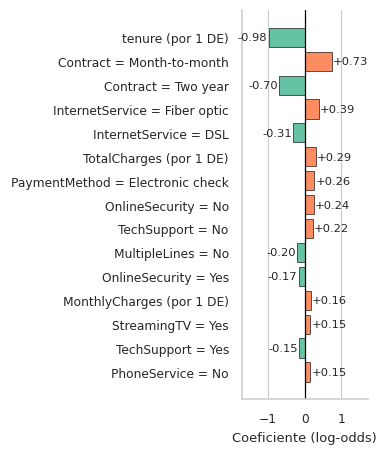

In [12]:
figura = graficos.figura_coeficientes(coeficientes, cantidad=15)
graficos.guardar_figura(figura, "p03_coeficientes_regresion_logistica.png")
plt.show()

**Lectura.** Los coeficientes más grandes corresponden a `tenure` (negativo: a más antigüedad, menos abandono), al tipo de contrato (`Month-to-month` aumenta el riesgo y `Two year` lo reduce) y al servicio de internet (`Fiber optic` lo aumenta). Después aparecen el pago con `Electronic check` y no tener `OnlineSecurity` ni `TechSupport`. Es el mismo patrón que se observó en el EDA de P1.

**Una advertencia sobre las columnas repetidas.** `InternetService = No` y las seis columnas `... = No internet service` valen 1 exactamente para los mismos clientes. Lo mismo ocurre con `PhoneService = No` y `MultipleLines = No phone service`. La regularización L2 reparte el efecto por igual entre columnas idénticas, y por eso todas reciben el mismo coeficiente (−0.0725 las siete de internet). Leídas una por una parecerían poco importantes; en conjunto no lo son. El contraste de la sección siguiente evita este problema.

### 9.2 Razones de odds frente a la categoría más frecuente

Para comparar categorías se parte de un **cliente de referencia** (mediana de las variables numéricas y categoría más frecuente de cada variable en Train), se cambia una sola variable y se mide cuánto cambia el logaritmo de los odds que estima el modelo. Cuando el cambio es a `InternetService = No` o `PhoneService = No`, se cambian también las columnas que dependen de ellas, porque en los datos siempre van juntas.

Una razón de odds (OR) menor que 1 indica menor propensión estimada al abandono que la categoría de referencia.

In [13]:
referencia = analisis.cliente_de_referencia(X_train)
print("Cliente de referencia:")
display(referencia.T.rename(columns={0: "Valor"}))

odds = analisis.razones_de_odds(modelo, X_train)
display(odds.round(3))

Cliente de referencia:


,Valor
gender,Male
SeniorCitizen,0
Partner,No
Dependents,No
tenure,29.0
PhoneService,Yes
MultipleLines,No
InternetService,Fiber optic
OnlineSecurity,No
OnlineBackup,No


,Variable,Categoría,Referencia,Diferencia de log-odds,Razón de odds
0,InternetService,No,Fiber optic,-1.647,0.193
1,Contract,Two year,Month-to-month,-1.434,0.238
2,Contract,One year,Month-to-month,-0.768,0.464
3,InternetService,DSL,Fiber optic,-0.701,0.496
4,PhoneService,No,Yes,0.641,1.898
5,OnlineSecurity,Yes,No,-0.413,0.662
6,PaymentMethod,Bank transfer (automatic),Electronic check,-0.393,0.675
7,PaymentMethod,Credit card (automatic),Electronic check,-0.371,0.690
8,TechSupport,Yes,No,-0.370,0.691
9,PaperlessBilling,No,Yes,-0.280,0.756


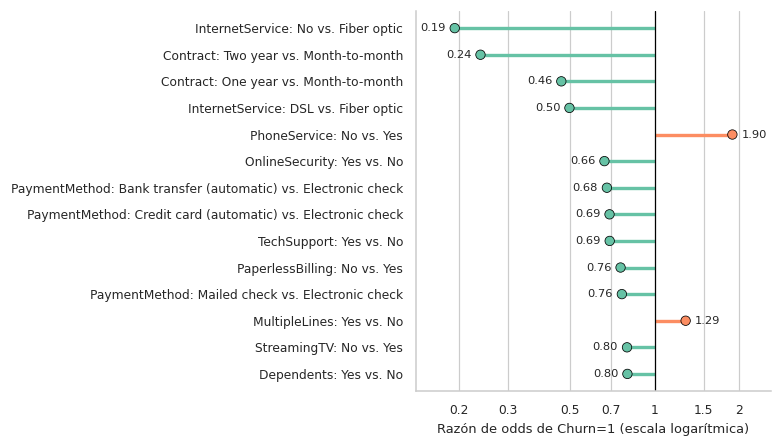

In [14]:
figura = graficos.figura_razones_de_odds(odds, cantidad=14)
graficos.guardar_figura(figura, "p03_razones_de_odds_regresion_logistica.png")
plt.show()

**Lectura.** Manteniendo fijo todo lo demás, el modelo estima que:

- un contrato de dos años multiplica los odds de abandono por **0.24** respecto de uno mensual, y uno de un año por **0.46**;
- tener DSL en lugar de fibra óptica los multiplica por **0.50**, y no tener internet por **0.19**;
- pagar con cualquier medio distinto de `Electronic check` los reduce (OR aproximadamente entre 0.68 y 0.76);
- contar con `OnlineSecurity` (0.66) o `TechSupport` (0.69) también los reduce;
- `gender` (1.05) y `Partner` (0.96) prácticamente no cambian la estimación, y `SeniorCitizen` aporta poco (1.18) una vez que se controla por el resto de variables.

Este último punto es interesante: en el EDA los adultos mayores abandonaban mucho más (41.7 % frente a 23.6 %), pero el modelo atribuye casi toda esa diferencia al tipo de contrato, al servicio y a la antigüedad que tienen esos clientes.

`PhoneService = No` aparece con OR = 1.90. Hay que leerlo con cuidado: es un efecto **condicional** al cargo mensual y a los demás servicios, no significa que quienes no tienen teléfono abandonen más en términos brutos.

Estas razones describen **asociaciones** aprendidas por el modelo en datos observacionales. No demuestran que cambiar el contrato de un cliente reduzca su probabilidad de abandono.

### 9.3 Variables numéricas

`tenure`, `MonthlyCharges` y `TotalCharges` están muy relacionadas (en P1: correlación de 0.83 entre `tenure` y `TotalCharges`, y `TotalCharges` es prácticamente `tenure × MonthlyCharges`). Por eso mover una sola "con las demás fijas" describe un cliente poco realista. Además de los coeficientes por desviación estándar, se evalúan dos escenarios coherentes.

In [15]:
display(analisis.efectos_numericos(modelo, X_train).round(3))

,Escenario,Diferencia de log-odds,Razón de odds
0,"tenure: +1 desviación estándar (24.7), resto fijo",-0.984,0.374
1,"MonthlyCharges: +1 desviación estándar (30.0), resto fijo",0.161,1.175
2,"TotalCharges: +1 desviación estándar (2280.1), resto fijo",0.293,1.340
3,+12 meses de antigüedad con el mismo cargo mensual,-0.370,0.690
4,+20 USD de cargo mensual durante toda la antigüedad,0.182,1.200


**Lectura.** El coeficiente de `tenure` es el mayor del modelo (OR = 0.37 por cada 24.7 meses), pero parte de ese efecto se compensa con el coeficiente positivo de `TotalCharges`, que crece junto con la antigüedad. En el escenario coherente, **12 meses más de antigüedad con el mismo cargo mensual** multiplican los odds por 0.69, y **20 USD más de cargo mensual** los multiplican por 1.20. Es decir: más antigüedad se asocia con menos abandono y un cargo mensual más alto con más abandono, como en el EDA.

### 9.4 Importancia por permutación (Validation)

Como complemento, se mide cuánto cae el desempeño en Validation cuando se desordena una variable original (las 19, antes del One-Hot Encoding). Se repite 30 veces por variable. A diferencia de los coeficientes, esta medida no se ve afectada por las columnas repetidas, porque se permuta la variable completa.

In [16]:
permutacion = analisis.importancia_por_permutacion(modelo, X_val, y_val, n_repeticiones=30)
display(permutacion.round(4))

,Variable,Caída de F1-score (media),Caída de F1-score (DE),Caída de ROC-AUC (media),Caída de ROC-AUC (DE)
0,tenure,0.1261,0.0148,0.1125,0.0088
1,Contract,0.0375,0.0120,0.0354,0.0070
2,InternetService,0.0144,0.0065,0.0148,0.0034
3,PaymentMethod,0.0096,0.0043,0.0050,0.0018
4,TotalCharges,0.0082,0.0063,0.0078,0.0022
5,MonthlyCharges,0.0049,0.0059,0.0034,0.0014
6,StreamingTV,0.0042,0.0034,0.0009,0.0009
7,PaperlessBilling,0.0037,0.0032,0.0039,0.0013
8,TechSupport,0.0037,0.0058,0.0037,0.0013
9,PhoneService,0.0034,0.0019,-0.0001,0.0005


**Lectura.** El modelo depende sobre todo de `tenure` (el F1 cae 0.126 al permutarla), luego de `Contract` (0.038) e `InternetService` (0.014). El resto de variables aporta menos de 0.01 cada una, y `gender` y `Partner` no aportan nada medible, lo que coincide con el EDA (tasas de abandono casi iguales entre hombres y mujeres).

Hay que tener en cuenta que, cuando dos variables contienen información parecida (por ejemplo `TotalCharges` y `tenure`), al permutar una el modelo todavía puede apoyarse en la otra, así que la importancia individual puede quedar subestimada.

### 9.5 ¿Se pueden leer las salidas como probabilidades?

In [17]:
display(analisis.resumen_de_probabilidades(y_val, {NOMBRE_LOGISTICA: (y_val_pred, y_val_proba)}).round(3).T)

Modelo,Regresión logística
Tasa real de abandono,0.265
Probabilidad media estimada,0.411
"Proporción de alertas (umbral 0,5)",0.407
Probabilidad media si Churn=1,0.667
Probabilidad media si Churn=0,0.318


**Lectura.** La probabilidad media que estima el modelo en Validation (0.411) es bastante mayor que la tasa real de abandono (0.265). Es una consecuencia directa de `class_weight="balanced"`: el modelo aprende como si ambas clases fueran igual de frecuentes. Sus salidas sirven para **ordenar** a los clientes por riesgo y para clasificar con el umbral de 0,5, pero no deben interpretarse como la probabilidad real de que un cliente abandone (no están calibradas).

## 10. Exportar resultados

In [18]:
rutas = [
    guardar_tabla(tabla, "resultados_regresion_logistica_grilla_validacion.csv", index=False),
    guardar_tabla(tabla_seleccionado, "resultados_regresion_logistica_validacion.csv"),
    guardar_tabla(matriz_val, "matriz_confusion_regresion_logistica_validacion.csv"),
    guardar_tabla(coeficientes, "coeficientes_regresion_logistica.csv"),
    guardar_tabla(odds, "razones_de_odds_regresion_logistica.csv", index=False),
    guardar_tabla(permutacion, "importancia_permutacion_regresion_logistica_validacion.csv", index=False),
    guardar_json(
        {
            "modelo": NOMBRE_LOGISTICA,
            "configuracion": numero,
            "hiperparametros": parametros,
            "criterio": "Mayor F1-score de Churn=1 en Validation (protocolo de P02)",
            "configuraciones_evaluadas": len(tabla),
            "configuraciones_empatadas": empatadas,
            "intercepto": intercepto,
            "metricas_train": metricas_train,
            "metricas_validation": metricas_val,
            "versiones": versiones(),
        },
        "configuracion_regresion_logistica.json",
    ),
]
print("Archivos creados en resultados/:")
for ruta in rutas:
    print(" -", ruta.name)
print("Figuras en resultados/figuras/: p03_busqueda_regresion_logistica.png, "
      "p03_coeficientes_regresion_logistica.png, p03_razones_de_odds_regresion_logistica.png")

Archivos creados en resultados/:
 - resultados_regresion_logistica_grilla_validacion.csv
 - resultados_regresion_logistica_validacion.csv
 - matriz_confusion_regresion_logistica_validacion.csv
 - coeficientes_regresion_logistica.csv
 - razones_de_odds_regresion_logistica.csv
 - importancia_permutacion_regresion_logistica_validacion.csv
 - configuracion_regresion_logistica.json
Figuras en resultados/figuras/: p03_busqueda_regresion_logistica.png, p03_coeficientes_regresion_logistica.png, p03_razones_de_odds_regresion_logistica.png


## 11. Conclusiones de esta parte

1. **Configuración seleccionada:** regresión logística con regularización L2, `C = 0.1` y `class_weight="balanced"`. En Validation obtiene F1 = 0.625, Precision = 0.517, Recall = 0.791, Accuracy = 0.748 y ROC-AUC = 0.836.
2. **Regularización:** importa poco en este problema. El desempeño es estable desde `C ≈ 0.01` y la brecha Train–Validation es mínima; L1 logra casi el mismo F1 con solo 7 coeficientes.
3. **Desbalance:** `class_weight="balanced"` es la decisión que más pesa. No mejora el ROC-AUC, pero cambia el equilibrio entre Precision y Recall a favor de detectar más abandonos, que es lo que premia el F1.
4. **Interpretación:** el modelo se apoya en la antigüedad, el tipo de contrato y el servicio de internet, y casi no usa `gender` ni `Partner`. Es coherente con el EDA de P1.
5. **Qué falta:** la configuración queda guardada en `resultados/configuracion_regresion_logistica.json`. El desempeño sobre Test se mide una sola vez en `P05_evaluacion_comparativa.ipynb`.